<a href="https://colab.research.google.com/github/dominicbarasa/Artificial-Intelligence-/blob/main/Week_6_Assignment_Discovering_Patterns_Concrete.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6 Assignment: Discovering Patterns in Data

**Name:** Dominic Barasa  
**Course:** AI for Science and Engineering  
**Project:** Prediction of Concrete Compressive Strength Using Machine Learning

## Objective

The objective of this assignment is to use unsupervised machine learning to discover groups of concrete mixtures with similar characteristics using the K-Means clustering algorithm.

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

print("Libraries imported successfully.")

Libraries imported successfully.


In [22]:
url = "https://raw.githubusercontent.com/HansenHan/ML_UCI_Concrete_Compressive_Strength/main/Concrete_Data.csv"

df = pd.read_csv(url)

df.columns = [
    "Cement",
    "Blast_Furnace_Slag",
    "Fly_Ash",
    "Water",
    "Superplasticizer",
    "Coarse_Aggregate",
    "Fine_Aggregate",
    "Age",
    "Compressive_Strength"
]

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1030, 9)


,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Compressive_Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


## Feature Selection

Four numerical variables were selected for clustering:

1. Cement content
2. Water content
3. Curing age
4. Concrete compressive strength

These variables were selected to investigate whether concrete mixtures can be grouped according to their cement content, water content, curing age, and measured strength.

Compressive strength is included as a feature for exploratory clustering. Therefore, the clusters are not independent predictions of strength; they describe patterns in the selected variables.

In [23]:
features = ["Cement", "Water", "Age", "Compressive_Strength"]

X = df[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original feature shape:", X.shape)
print("Scaled feature shape:", X_scaled.shape)
print("\nScaled feature means (approximately zero):")
print(np.round(X_scaled.mean(axis=0), 3))

Original feature shape: (1030, 4)
Scaled feature shape: (1030, 4)

Scaled feature means (approximately zero):
[-0. -0.  0. -0.]


In [24]:
cluster_numbers = range(2, 9)
inertia_values = []
silhouette_values = []

for k in cluster_numbers:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(X_scaled, labels)
    )

comparison = pd.DataFrame({
    "Number of Clusters": list(cluster_numbers),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

display(comparison.round(3))

,Number of Clusters,Inertia,Silhouette Score
0,2,2957.356,0.299
1,3,2128.878,0.342
2,4,1753.537,0.275
3,5,1474.026,0.275
4,6,1338.816,0.269
5,7,1235.250,0.247
6,8,1145.484,0.253


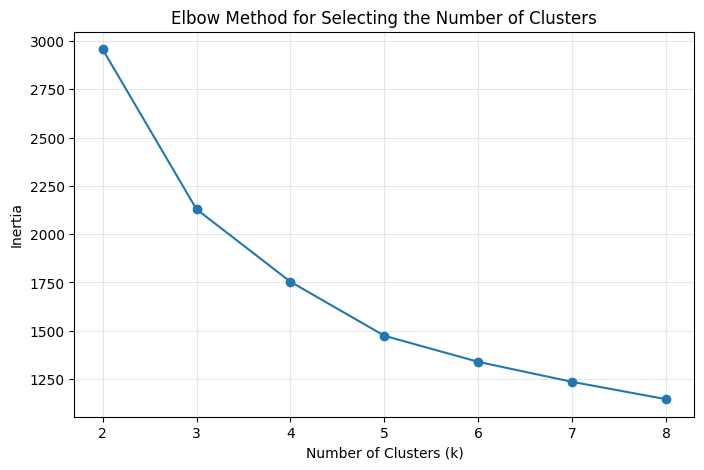

In [25]:
plt.figure(figsize=(8, 5))
plt.plot(
    list(cluster_numbers),
    inertia_values,
    marker="o"
)
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Selecting the Number of Clusters")
plt.xticks(list(cluster_numbers))
plt.grid(True, alpha=0.3)
plt.show()

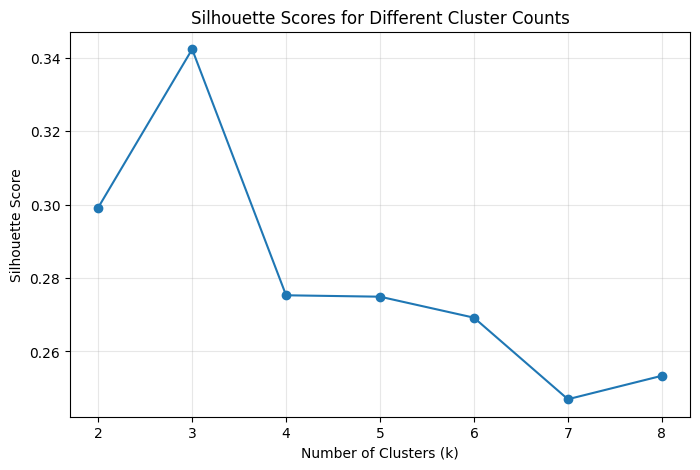

Cluster count with the highest silhouette score: 3


In [26]:
plt.figure(figsize=(8, 5))
plt.plot(
    list(cluster_numbers),
    silhouette_values,
    marker="o"
)
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Scores for Different Cluster Counts")
plt.xticks(list(cluster_numbers))
plt.grid(True, alpha=0.3)
plt.show()

best_silhouette_k = list(cluster_numbers)[
    np.argmax(silhouette_values)
]

print("Cluster count with the highest silhouette score:",
      best_silhouette_k)

In [27]:
chosen_k = best_silhouette_k

kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Chosen number of clusters:", chosen_k)
print("\nNumber of observations in each cluster:")
print(df["Cluster"].value_counts().sort_index())

Chosen number of clusters: 3

Number of observations in each cluster:
Cluster
0    344
1    621
2     65
Name: count, dtype: int64


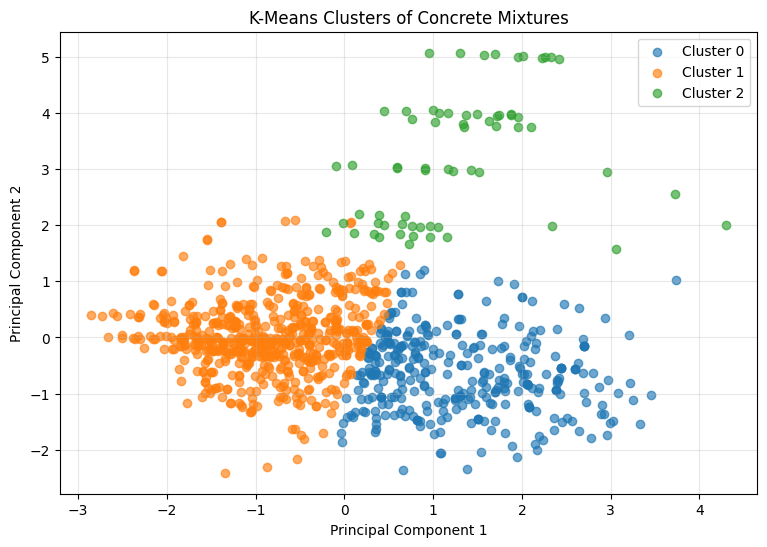

Variance represented by the two components: 73.64 %


In [28]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

for cluster_id in sorted(df["Cluster"].unique()):
    mask = df["Cluster"] == cluster_id

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Cluster {cluster_id}",
        alpha=0.65
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters of Concrete Mixtures")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(
    "Variance represented by the two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [29]:
cluster_summary = df.groupby("Cluster")[features].mean().round(2)

display(cluster_summary)

,Cement,Water,Age,Compressive_Strength
Cluster,,,,
0,365.76,166.14,40.07,51.71
1,228.74,186.82,27.90,26.17
2,334.38,213.02,244.92,43.91


In [30]:
strength_summary = df.groupby("Cluster")[
    "Compressive_Strength"
].agg(["count", "mean", "median", "min", "max"]).round(2)

display(strength_summary)

,count,mean,median,min,max
Cluster,,,,,
0,344,51.71,51.30,22.75,82.60
1,621,26.17,25.89,2.33,53.72
2,65,43.91,42.13,24.10,74.17


## Discussion and Interpretation

K-Means clustering was applied to four standardized numerical variables: cement content, water content, curing age, and concrete compressive strength.

The elbow method and silhouette scores were used to investigate different numbers of clusters. Based on these results, **3 clusters** were selected for further analysis because they produced the highest silhouette score of **0.342**.

The clustering visualization shows how the concrete mixtures were grouped according to similarities in the selected variables. The cluster summary table was used to compare the average characteristics of the groups.

**Cluster 0** had the highest average cement content (365.76 kg/m³), the lowest average water content (166.14 kg/m³), an average curing age of 40.07 days, and the highest average compressive strength (51.71 MPa).

**Cluster 1** had the lowest average cement content (228.74 kg/m³), an average water content of 186.82 kg/m³, an average curing age of 27.90 days, and the lowest average compressive strength (26.17 MPa).

**Cluster 2** had an average cement content of 334.38 kg/m³, the highest average water content (213.02 kg/m³), the longest average curing age (244.92 days), and an average compressive strength of 43.91 MPa.

These groups may represent different patterns of concrete mix composition, curing age, and measured strength. However, the cluster labels do not automatically represent established concrete grades or approved mix designs.

Clustering is an unsupervised learning method because it identifies patterns without using predefined group labels. The findings are exploratory and would require further engineering evaluation before being used for practical decisions.

## Conclusion

This assignment demonstrated how K-Means clustering can be used as an unsupervised machine learning technique to discover patterns in concrete compressive strength data. Four numerical features—cement content, water content, curing age, and compressive strength—were standardized before clustering. Different cluster numbers were evaluated using the elbow method and silhouette scores, and **three clusters were selected because they achieved the highest silhouette score of 0.342** among the tested options.

The cluster analysis revealed distinct patterns in the concrete mixtures. **Cluster 0** recorded the highest average compressive strength of **51.71 MPa**, together with the highest average cement content and lowest average water content. **Cluster 1** had the lowest average compressive strength of **26.17 MPa** and the lowest average cement content. **Cluster 2** represented mixtures with the longest average curing age of approximately **245 days** and an average compressive strength of **43.91 MPa**. The Principal Component Analysis (PCA) visualization represented **73.64% of the variance** in the selected features, providing a useful two-dimensional view of the clustering patterns.

Overall, the findings demonstrate that unsupervised machine learning can help identify similarities and differences among concrete mixtures and support exploratory data analysis in civil engineering. However, the clusters are based on the selected variables and should not be interpreted as approved concrete grades or mix designs. Further engineering assessment would be necessary before using these patterns to guide practical construction decisions.

## Dataset Source

UCI Machine Learning Repository. *Concrete Compressive Strength Dataset.*

https://archive.ics.uci.edu/dataset/165/concrete%2Bcompressive%2Bstrength